In [23]:
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer,  TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split

import nltk
from nltk import word_tokenize
from nltk.stem import WordNetLemmatizer, PorterStemmer
from nltk.corpus import wordnet


In [24]:
nltk.download("wordnet")
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('omw-1.4')

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [25]:
from google.colab import drive, files
import numpy as np
import pandas as pd
import os

drive.mount('/content/gdrive/')

Drive already mounted at /content/gdrive/; to attempt to forcibly remount, call drive.mount("/content/gdrive/", force_remount=True).


In [26]:
PROJECT_FOLDER = "/content/gdrive/MyDrive/Colab Notebooks/MSDS650/Homework3"
os.chdir(PROJECT_FOLDER)
print("Current dir: ", os.getcwd())

Current dir:  /content/gdrive/MyDrive/Colab Notebooks/MSDS650/Homework3


In [44]:
#np.random.seed(123)
data = pd.read_csv('spam.csv') #,encoding='latin-1'if needed
data.head()

,labels,data
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [45]:
inputs = data['data']
labels = data['labels']
labels.value_counts()

,count
labels,
ham,4825
spam,747


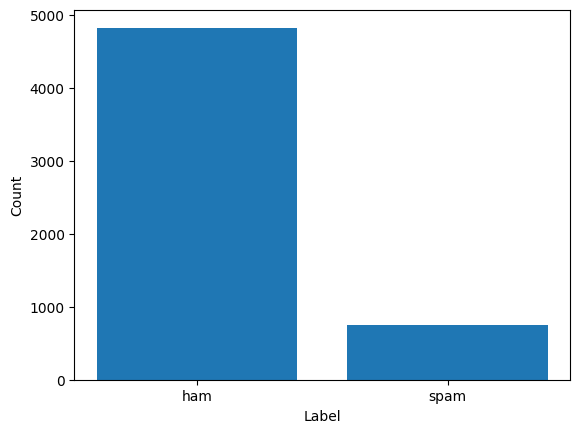

In [46]:
plt.bar(labels.value_counts().index, labels.value_counts())
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()

In [39]:
inputs_train, inputs_test, Ytrain, Ytest = train_test_split(
    inputs, labels, random_state=123)

In [40]:
vectorizer = CountVectorizer() # with default arguments

In [41]:
Xtrain = vectorizer.fit_transform(inputs_train)
Xtest = vectorizer.transform(inputs_test)

In [42]:
Xtrain.shape

(4179, 7419)

In [48]:
(Xtrain != 0).sum()

np.int64(55551)

In [47]:
(Xtrain != 0).sum() / np.prod(Xtrain.shape)

np.float64(0.0017917364923320702)

In [49]:
model = MultinomialNB()
model.fit(Xtrain, Ytrain)
print("train score:", model.score(Xtrain, Ytrain))
print("test score:", model.score(Xtest, Ytest))

train score: 0.9937784158889686
test score: 0.9834888729361091


In [50]:
# with stopwords
vectorizer = CountVectorizer(stop_words='english')
Xtrain = vectorizer.fit_transform(inputs_train)
Xtest = vectorizer.transform(inputs_test)
model = MultinomialNB()
model.fit(Xtrain, Ytrain)
print("train score:", model.score(Xtrain, Ytrain))
print("test score:", model.score(Xtest, Ytest))

train score: 0.994256999282125
test score: 0.9885139985642498


b.

In [51]:
def get_wordnet_pos(treebank_tag):
  if treebank_tag.startswith('J'):
    return wordnet.ADJ
  elif treebank_tag.startswith('V'):
    return wordnet.VERB
  elif treebank_tag.startswith('N'):
    return wordnet.NOUN
  elif treebank_tag.startswith('R'):
    return wordnet.ADV
  else:
    return wordnet.NOUN

In [52]:
class LemmaTokenizer:
  def __init__(self):
    self.wnl = WordNetLemmatizer()
  def __call__(self, doc):
    tokens = word_tokenize(doc)
    words_and_tags = nltk.pos_tag(tokens)
    return [self.wnl.lemmatize(word, pos=get_wordnet_pos(tag)) \
            for word, tag in words_and_tags]

In [53]:
# with lemmatization
vectorizer_lem = CountVectorizer(tokenizer=LemmaTokenizer())
Xtrain_lem = vectorizer_lem.fit_transform(inputs_train)
Xtest_lem = vectorizer_lem.transform(inputs_test)
model_lem = MultinomialNB()
model_lem.fit(Xtrain_lem, Ytrain)
print("train score:", model_lem.score(Xtrain_lem, Ytrain))
print("test score:", model_lem.score(Xtest_lem, Ytest))

/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


train score: 0.9921033740129217
test score: 0.9849246231155779


In [54]:
class StemTokenizer:
  def __init__(self):
    self.porter = PorterStemmer()
  def __call__(self, doc):
    tokens = word_tokenize(doc)
    words_and_tags = nltk.pos_tag(tokens)
    return [self.porter.stem(t) for t in tokens]

In [55]:
# with stemming
vectorizer_stem = CountVectorizer(tokenizer=StemTokenizer())
Xtrain_stem = vectorizer_stem.fit_transform(inputs_train)
Xtest_stem = vectorizer_stem.transform(inputs_test)
model_stem = MultinomialNB()
model_stem.fit(Xtrain_stem, Ytrain)
print("train score:", model_stem.score(Xtrain_stem, Ytrain))
print("test score:", model_stem.score(Xtest_stem, Ytest))

/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


train score: 0.9923426657094999
test score: 0.9856424982053122


In [ ]:
#sample_msg = [“Congratulations you have won a 1000 dollars gift card Click here to claim your prize”]

In [56]:
sample_msg = ["Congratulations you have won a 1000 dollars gift card Click here to claim your prize"]

lemma_tokenizer = LemmaTokenizer()
stem_tokenizer = StemTokenizer()

lemma_tokens = lemma_tokenizer(sample_msg[0])  # Pass the string, not the list
stem_tokens = stem_tokenizer(sample_msg[0])  # Pass the string, not the list

print("Lemma Tokens:", lemma_tokens)
print("Stem Tokens:", stem_tokens)

Lemma Tokens: ['Congratulations', 'you', 'have', 'win', 'a', '1000', 'dollar', 'gift', 'card', 'Click', 'here', 'to', 'claim', 'your', 'prize']
Stem Tokens: ['congratul', 'you', 'have', 'won', 'a', '1000', 'dollar', 'gift', 'card', 'click', 'here', 'to', 'claim', 'your', 'prize']


c.

In [63]:
np.random.seed(123)
data_c = pd.read_csv('spam.csv')
print(data_c.columns)

Index(['labels', 'data'], dtype='object')


In [64]:
np.random.seed(123)
data_c = pd.read_csv('spam.csv')

data_c = data_c[['labels', 'data']]
data_c = data_c.rename(columns={'labels': 'label', 'data': 'text'})

data_c['b_labels'] = data_c['label'].map({'ham': 0, 'spam': 1})

print(data_c.head())

  label                                               text  b_labels
0   ham  Go until jurong point, crazy.. Available only ...         0
1   ham                      Ok lar... Joking wif u oni...         0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...         1
3   ham  U dun say so early hor... U c already then say...         0
4   ham  Nah I don't think he goes to usf, he lives aro...         0


In [65]:
inputs_c = data_c['text']
labels_c = data_c['b_labels']

inputs_train_c, inputs_test_c, Ytrain_c, Ytest_c = train_test_split(
    inputs_c, labels_c, test_size=0.2, random_state=123)

print("inputs_train_c shape:", inputs_train_c.shape)
print("inputs_test_c shape:", inputs_test_c.shape)
print("Ytrain_c shape:", Ytrain_c.shape)
print("Ytest_c shape:", Ytest_c.shape)

inputs_train_c shape: (4457,)
inputs_test_c shape: (1115,)
Ytrain_c shape: (4457,)
Ytest_c shape: (1115,)


In [66]:
# Vectorize using CountVectorizer (default settings)
vectorizer_c = CountVectorizer()
Xtrain_count = vectorizer_c.fit_transform(inputs_train_c)
Xtest_count = vectorizer_c.transform(inputs_test_c)

print("CountVectorizer (default) - Xtrain_count shape:", Xtrain_count.shape)
print("CountVectorizer (default) - Xtest_count shape:", Xtest_count.shape)

CountVectorizer (default) - Xtrain_count shape: (4457, 7682)
CountVectorizer (default) - Xtest_count shape: (1115, 7682)


In [67]:
# Vectorize using CountVectorizer with lemmatization
vectorizer_lem = CountVectorizer(tokenizer=LemmaTokenizer())
Xtrain_lem = vectorizer_lem.fit_transform(inputs_train_c)
Xtest_lem = vectorizer_lem.transform(inputs_test_c)

print("CountVectorizer (lemmatization) - Xtrain_lem shape:", Xtrain_lem.shape)
print("CountVectorizer (lemmatization) - Xtest_lem shape:", Xtest_lem.shape)

/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


CountVectorizer (lemmatization) - Xtrain_lem shape: (4457, 7500)
CountVectorizer (lemmatization) - Xtest_lem shape: (1115, 7500)


In [68]:
# Vectorize using CountVectorizer with stemming
vectorizer_stem = CountVectorizer(tokenizer=StemTokenizer())
Xtrain_stem = vectorizer_stem.fit_transform(inputs_train_c)
Xtest_stem = vectorizer_stem.transform(inputs_test_c)

print("CountVectorizer (stemming) - Xtrain_stem shape:", Xtrain_stem.shape)
print("CountVectorizer (stemming) - Xtest_stem shape:", Xtest_stem.shape)

CountVectorizer (stemming) - Xtrain_stem shape: (4457, 7204)
CountVectorizer (stemming) - Xtest_stem shape: (1115, 7204)


In [69]:
# Vectorize using TfidfVectorizer (default settings)
vectorizer_tfidf = TfidfVectorizer()
Xtrain_tfidf = vectorizer_tfidf.fit_transform(inputs_train_c)
Xtest_tfidf = vectorizer_tfidf.transform(inputs_test_c)

print("TfidfVectorizer (default) - Xtrain_tfidf shape:", Xtrain_tfidf.shape)
print("TfidfVectorizer (default) - Xtest_tfidf shape:", Xtest_tfidf.shape)

TfidfVectorizer (default) - Xtrain_tfidf shape: (4457, 7682)
TfidfVectorizer (default) - Xtest_tfidf shape: (1115, 7682)


In [70]:
# Vectorize using TfidfVectorizer (max_features=2000)
vectorizer_tfidf_2000 = TfidfVectorizer(max_features=2000)
Xtrain_tfidf_2000 = vectorizer_tfidf_2000.fit_transform(inputs_train_c)
Xtest_tfidf_2000 = vectorizer_tfidf_2000.transform(inputs_test_c)

print("TfidfVectorizer (max_features=2000) - Xtrain_tfidf_2000 shape:", Xtrain_tfidf_2000.shape)
print("TfidfVectorizer (max_features=2000) - Xtest_tfidf_2000 shape:", Xtest_tfidf_2000.shape)

TfidfVectorizer (max_features=2000) - Xtrain_tfidf_2000 shape: (4457, 2000)
TfidfVectorizer (max_features=2000) - Xtest_tfidf_2000 shape: (1115, 2000)


d.

In [72]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import f1_score
import numpy as np

In [74]:

model_lr = LogisticRegression(max_iter=1000)

# Hyperparameter grid
param_grid = {'C': [1, 0.1, 0.01]}

# Vectorizers and corresponding train data
vectorizers = {
    "CountVectorizer (default)": Xtrain_count,
    "CountVectorizer (lemmatization)": Xtrain_lem,
    "CountVectorizer (stemming)": Xtrain_stem,
    "TfidfVectorizer (default)": Xtrain_tfidf,
    "TfidfVectorizer (max_features=2000)": Xtrain_tfidf_2000
}

# Perform grid search with 5-fold cross-validation for each vectorizer
for name, X_train in vectorizers.items():
    grid_search = GridSearchCV(model_lr, param_grid, cv=5, scoring='f1')
    grid_search.fit(X_train, Ytrain_c)

    print(f"{name} - Best C: {grid_search.best_params_['C']}")
    print(f"{name} - Best F1 Score: {grid_search.best_score_:.4f}\n")

CountVectorizer (default) - Best C: 1
CountVectorizer (default) - Best F1 Score: 0.9305

CountVectorizer (lemmatization) - Best C: 1
CountVectorizer (lemmatization) - Best F1 Score: 0.9261

CountVectorizer (stemming) - Best C: 1
CountVectorizer (stemming) - Best F1 Score: 0.9284

TfidfVectorizer (default) - Best C: 1
TfidfVectorizer (default) - Best F1 Score: 0.8203

TfidfVectorizer (max_features=2000) - Best C: 1
TfidfVectorizer (max_features=2000) - Best F1 Score: 0.8641



In [75]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Train the best model on the entire training set
best_model = LogisticRegression(C=1, max_iter=1000)
best_model.fit(Xtrain_count, Ytrain_c)

y_pred = best_model.predict(Xtest_count)

print("Classification Report (Test Set):")
print(classification_report(Ytest_c, y_pred))

print("\nConfusion Matrix (Test Set):")
print(confusion_matrix(Ytest_c, y_pred))

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       982
           1       0.99      0.86      0.92       133

    accuracy                           0.98      1115
   macro avg       0.99      0.93      0.96      1115
weighted avg       0.98      0.98      0.98      1115


Confusion Matrix (Test Set):
[[981   1]
 [ 18 115]]


e.

In [77]:
from sklearn.ensemble import RandomForestClassifier

In [79]:
param_grid_e = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

# random forest
rf_model = RandomForestClassifier(random_state=123)

# vectorizers
vectorizers_rf = {
    "TF-IDF (max_features=2000)": Xtrain_tfidf_2000,
    "CountVectorizer (stemming)": Xtrain_stem
}

# perform grid search with 5-fold cross-validation for each vectorizer
for name, X_train in vectorizers_rf.items():
    grid_search_rf = GridSearchCV(rf_model, param_grid_e, cv=5, scoring='f1')
    grid_search_rf.fit(X_train, Ytrain_c)

    print(f"{name} - Best Hyperparameters: {grid_search_rf.best_params_}")
    print(f"{name} - Best F1 Score: {grid_search_rf.best_score_:.4f}\n")

TF-IDF (max_features=2000) - Best Hyperparameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200}
TF-IDF (max_features=2000) - Best F1 Score: 0.9267

CountVectorizer (stemming) - Best Hyperparameters: {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 200}
CountVectorizer (stemming) - Best F1 Score: 0.8947



In [80]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score

param_grid_e = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}

rf_model = RandomForestClassifier(random_state=123)

vectorizers_rf = {
    "TF-IDF (max_features=2000)": Xtrain_tfidf_2000,
    "CountVectorizer (stemming)": Xtrain_stem
}

for name, X_train in vectorizers_rf.items():
    random_search_rf = RandomizedSearchCV(
        rf_model,
        param_grid_e,
        n_iter=10,  # 10 iterations
        cv=5,
        scoring='f1',
        random_state=123
    )
    random_search_rf.fit(X_train, Ytrain_c)

    print(f"{name} - Best Hyperparameters: {random_search_rf.best_params_}")
    print(f"{name} - Best F1 Score: {random_search_rf.best_score_:.4f}\n")

/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 27 is smaller than n_iter=100. Running 27 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


TF-IDF (max_features=2000) - Best Hyperparameters: {'n_estimators': 200, 'min_samples_split': 10, 'max_depth': None}
TF-IDF (max_features=2000) - Best F1 Score: 0.9267



/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_search.py:317: UserWarning: The total space of parameters 27 is smaller than n_iter=100. Running 27 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


CountVectorizer (stemming) - Best Hyperparameters: {'n_estimators': 200, 'min_samples_split': 10, 'max_depth': None}
CountVectorizer (stemming) - Best F1 Score: 0.8947



f.

In [81]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Train the best model on the entire training set
best_model_lr = LogisticRegression(C=1, max_iter=100)
best_model_lr.fit(Xtrain_count, Ytrain_c)

# Make predictions on the test set
y_pred_lr = best_model_lr.predict(Xtest_count)

# Evaluate the model
accuracy_lr = accuracy_score(Ytest_c, y_pred_lr)
precision_lr = precision_score(Ytest_c, y_pred_lr)
recall_lr = recall_score(Ytest_c, y_pred_lr)
f1_lr = f1_score(Ytest_c, y_pred_lr)

# Print the results
print("Logistic Regression (CountVectorizer default, C=1) - Test Set Evaluation:")
print(f"Accuracy: {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall: {recall_lr:.4f}")
print(f"F1-score: {f1_lr:.4f}")

print("\nClassification Report (Test Set):")
print(classification_report(Ytest_c, y_pred_lr))

print("\nConfusion Matrix (Test Set):")
print(confusion_matrix(Ytest_c, y_pred_lr))

Logistic Regression (CountVectorizer default, C=1) - Test Set Evaluation:
Accuracy: 0.9830
Precision: 0.9914
Recall: 0.8647
F1-score: 0.9237

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       982
           1       0.99      0.86      0.92       133

    accuracy                           0.98      1115
   macro avg       0.99      0.93      0.96      1115
weighted avg       0.98      0.98      0.98      1115


Confusion Matrix (Test Set):
[[981   1]
 [ 18 115]]


In [82]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Train the best Random Forest model on the entire training set
best_model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=10,
    random_state=123
)
best_model_rf.fit(Xtrain_tfidf_2000, Ytrain_c)

# Make predictions on the test set
y_pred_rf = best_model_rf.predict(Xtest_tfidf_2000)

# Evaluate the model
accuracy_rf = accuracy_score(Ytest_c, y_pred_rf)
precision_rf = precision_score(Ytest_c, y_pred_rf)
recall_rf = recall_score(Ytest_c, y_pred_rf)
f1_rf = f1_score(Ytest_c, y_pred_rf)

# Print the results
print("Random Forest (TF-IDF max_features=2000) - Test Set Evaluation:")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-score: {f1_rf:.4f}")

print("\nClassification Report (Test Set):")
print(classification_report(Ytest_c, y_pred_rf))

print("\nConfusion Matrix (Test Set):")
print(confusion_matrix(Ytest_c, y_pred_rf))

Random Forest (TF-IDF max_features=2000) - Test Set Evaluation:
Accuracy: 0.9785
Precision: 0.9910
Recall: 0.8271
F1-score: 0.9016

Classification Report (Test Set):
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       982
           1       0.99      0.83      0.90       133

    accuracy                           0.98      1115
   macro avg       0.98      0.91      0.94      1115
weighted avg       0.98      0.98      0.98      1115


Confusion Matrix (Test Set):
[[981   1]
 [ 23 110]]


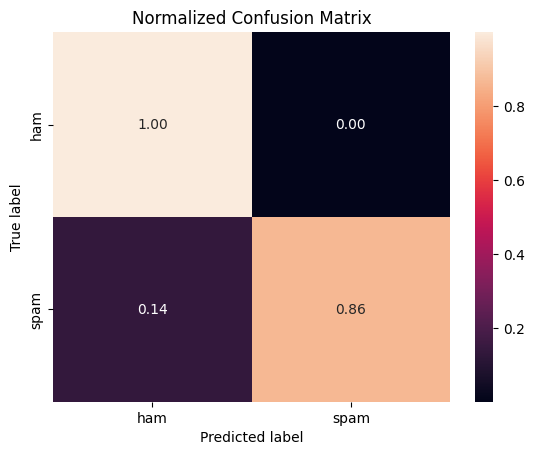

In [83]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(Ytest_c, y_pred_lr, normalize='true')

sns.heatmap(cm, annot=True, fmt='.2f', xticklabels=['ham', 'spam'], yticklabels=['ham', 'spam'])
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title('Normalized Confusion Matrix')
plt.show()

g.

In [84]:
test_df = pd.DataFrame({'text': inputs_test_c, 'true_label': Ytest_c, 'predicted_label': y_pred_lr})

# Identify false positives and false negatives
false_positives = test_df[(test_df['true_label'] == 0) & (test_df['predicted_label'] == 1)]
false_negatives = test_df[(test_df['true_label'] == 1) & (test_df['predicted_label'] == 0)]

print("False Positives (Ham Classified as Spam):")
print(false_positives['text'].to_string())
print("\nFalse Negatives (Spam Classified as Ham):")
print(false_negatives['text'].to_string())

False Positives (Ham Classified as Spam):
3690    Sir, i am waiting for your call, once free ple...

False Negatives (Spam Classified as Ham):
671            SMS. ac sun0819 posts HELLO:\You seem cool
730     Email AlertFrom: Jeri StewartSize: 2KBSubject:...
1448    As a registered optin subscriber ur draw 4 å£1...
1268    Can U get 2 phone NOW? I wanna chat 2 set up m...
2769    Burger King - Wanna play footy at a top stadiu...
5370    dating:i have had two of these. Only started a...
2246    Hi ya babe x u 4goten bout me?' scammers getti...
1673    Monthly password for wap. mobsi.com is 391784....
2401    Babe: U want me dont u baby! Im nasty and have...
3130    LookAtMe!: Thanks for your purchase of a video...
2351    Download as many ringtones as u like no restri...
4014    You will be receiving this week's Triple Echo ...
606     XCLUSIVE@CLUBSAISAI 2MOROW 28/5 SOIREE SPECIAL...
5449    Latest News! Police station toilet stolen, cop...
1499    SMS. ac JSco: Energy is high, but u m